# Market experiment: the DFM and its conditioning on daily US equity returns

This notebook applies the pipeline of the [synthetic notebook](synthetic_dfm_conditional_benchmark.ipynb)
to market data, with the same dimensions: $d=500$ assets, $k=8$ factors and 2,500 training
observations. It trains DFM (MLP), DFM (Gaussian + MLP) and DFM (Regimes + MLP) on daily
returns, freezes DFM (Regimes + MLP), and conditions it on a loss of the equal-weight portfolio
at the 5% and 1% levels. The three conditional models of the synthetic notebook are compared: CDG-ML,
Refined CDG-ML, and Refined CDG-ML with a sequential Monte Carlo (SMC) correction.

Market returns have no exact law. The unconditional reference is a set of hold-out market
days. The conditional references are DFM rejection sampling, the law every conditional model
targets, and the hold-out market days in the event. The tables and their metrics are those of the
synthetic notebook, with the market days in place of the exact law. The formulas of the DFM, of H
and of the samplers are in [METHODS.md](METHODS.md); only what differs from the synthetic notebook
is described here.

**Sources.** The DFM follows Chen et al. (2025); the terminal-event probability $H$, its Doob
guidance and CDG-ML follow Guo et al. (2026). The Gaussian + MLP and Regimes + MLP networks and their
linear refit, the five refinements and the exact final step are project adaptations; the regimes
are a scale mixture of Gaussians (Andrews et al., 1974). The SMC correction uses H as
twisting function (Wu et al., 2023).

## Configuration

`MODE="standard"` is the experiment; `MODE="smoke"` runs the same cells on 12 assets with
reduced budgets. Both use the configuration of the synthetic notebook (`notebook_config`). Set
`SAVED_RUN` to the folder of a finished run to display its saved figures and tables without
computing anything.

| Setting | Smoke | Standard (default) |
| --- | ---: | ---: |
| Assets / factors | 12 / 8 | 500 / 8 |
| Training / validation / evaluation days | 2,048 / 512 / 512 | 2,500 / 750 / 3,000 |
| DFM epochs / hidden widths | 15 / (32, 32) | 1,500 / (64, 64) |
| Volatility regimes (factor × residual scales) | 4 × 3 | 4 × 3 |
| Gaussian + MLP and Regimes + MLP: analytic part / knots of the linear refit | fixed / 12 | fixed / 12 |
| Noise draws per validation day / decay of the averaged weights | 8 / 0.999 | 8 / 0.999 |
| Integration steps | 100 | 400 |
| H train / validation / test trajectories | 2,048 / 1,024 / 1,024 | 40,000 / 2,000 / 2,000 |
| H epochs / hidden widths (validation every 157 optimizer steps) | 10 / (64, 64) | 50 / (64, 64) |
| Rows per conditional model, SMC particles | 512 | 3,000 |
| Accepted samples per DFM rejection stream (5% / 1%) | 128 / 64 | 1,000 / 1,000 |
| Proposal cap per DFM rejection stream (5% / 1%) | 25,600 / 64,000 | 200,000 / 1,000,000 |

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from dataclasses import asdict, replace
import os
import sys

import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "DFM.py").exists():
    raise RuntimeError("Run this notebook with the repository as working directory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from market_benchmark.data import load_or_build_panel, split_panel
from market_benchmark.unconditional import run_market_unconditional, show_market_unconditional
from synthetic_benchmark.configuration import network_config, notebook_config
from synthetic_benchmark.reporting import DFM_LABELS, format_return

In [2]:
MODE = os.environ.get("MARKET_MODE", "standard")  # "smoke": 12 assets and reduced budgets.
# Folder of a finished run to display instead of computing; None computes a new run.
SAVED_RUN = os.environ.get("MARKET_SAVED_RUN")
# The panel is built from the raw prices on first use, then read from this file.
PANEL_PATH = Path(os.environ.get("MARKET_PANEL", ROOT / "data" / "processed" / "market_panel.npz"))
# "random": days assigned by a seeded permutation; "chronological": most recent days held out.
SPLIT, SPLIT_SEED = "random", 912
# The DFM recipe of the synthetic notebook (synthetic_benchmark.configuration.DFM_RECIPE): per-asset
# standardization, PCA initialization, staged loading updates, log-spaced noising times with noise-variance
# weights, 8 validation noise draws and averaged weights. DFM (Regimes + MLP) has 4 factor and 3 residual scales.
CONFIG = notebook_config(MODE)
# DFM (Gaussian + MLP) and DFM (Regimes + MLP) keep their analytic part at its fit to the training days,
# train only their MLP and then refit the linear part of g (synthetic_benchmark.configuration.NETWORK_SETTINGS).
# The three DFMs are trained on the same days; guidance runs on DFM (Regimes + MLP).
DFM_NETWORKS = ("mlp", "gaussian_mlp", "regime_mlp")
GUIDED_NETWORK = "regime_mlp"
OUTPUT = Path(SAVED_RUN) if SAVED_RUN else ROOT / "artifacts" / "market_benchmark" / (
    MODE + "_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
)
display(pd.DataFrame({DFM_LABELS[network]: asdict(network_config(CONFIG, network))
                      for network in DFM_NETWORKS}).rename_axis("Effective DFM configuration"))

,DFM (MLP),DFM (Gaussian + MLP),DFM (Regimes + MLP)
Effective DFM configuration,,,
mode,standard,standard,standard
d,500,500,500
k,8,8,8
seeds,"(42,)","(42,)","(42,)"
cases,"(gaussian,)","(gaussian,)","(gaussian,)"
n_train,2500,2500,2500
n_val,750,750,750
n_eval,3000,3000,3000
dfm_epochs,1500,1500,1500


## 1. Build the market panel

**Data.** Daily adjusted closing prices from Yahoo Finance for the members of the S&P 500,
S&P 400 and S&P 600 indices as of October 2026, from December 1999 to December 2025. Returns
are simple daily returns, $R_{i,t}=P_{i,t}/P_{i,t-1}-1$.

**Assets.** The panel keeps the last 6,250 trading days and the assets with a price on every
one of them and at most 5% of unchanged prices, which removes stale quotes. Assets are taken
from the S&P 500 first, then from the S&P 400, alphabetically, until $d=500$ are found.

**Days.** The days are split into 2,500 training, 750 validation and 3,000 evaluation days by
a seeded random permutation. The DFM treats daily returns as independent draws of one law, so
the three sets are exchangeable draws of the same period, as in the synthetic experiment. The
evaluation days never enter training or model selection. `SPLIT="chronological"` holds out
the most recent days instead, which also measures how the law changes in time.

**Event.** With $w=\mathbf 1/d$, the event is $w^\top R\le C_q$, where $C_q$ is the empirical
$q$-quantile of the equal-weight portfolio return over the training days, $q\in\{0.05,0.01\}$.

**Survivorship.** The panel contains today's index members with a complete history. It
describes the daily returns of companies that survived, not an investable historical universe.

In [3]:
panel = load_or_build_panel(PANEL_PATH)
if CONFIG.d < panel.d:
    panel = panel.first_assets(CONFIG.d)
split = split_panel(panel, CONFIG.n_train, CONFIG.n_val, CONFIG.n_eval, split=SPLIT, seed=SPLIT_SEED)

from market_benchmark.conditional import event_threshold

hold_out_portfolio = split.evaluation @ split.weights
display(pd.Series({
    "Assets": f"{panel.d:,}",
    "Days used": f"{split.info['first_day']} to {split.info['last_day']}",
    "Training / validation / evaluation days": f"{CONFIG.n_train:,} / {CONFIG.n_val:,} / {CONFIG.n_eval:,}",
    "Split": SPLIT,
    "5% threshold of the portfolio return (training days)": format_return(event_threshold(split, 0.05)),
    "1% threshold of the portfolio return (training days)": format_return(event_threshold(split, 0.01)),
    "Hold-out days in the 5% / 1% event": " / ".join(
        f"{int((hold_out_portfolio <= event_threshold(split, q)).sum()):,}" for q in (0.05, 0.01)),
}, name="Market panel").to_frame())

,Market panel
Assets,500
Days used,2001-02-26 to 2025-12-31
Training / validation / evaluation days,"2,500 / 750 / 3,000"
Split,random
5% threshold of the portfolio return (training days),-1.76%
1% threshold of the portfolio return (training days),-3.32%
Hold-out days in the 5% / 1% event,187 / 46


## 2. Train and sample the unconditional DFM

DFM (MLP), DFM (Gaussian + MLP) and DFM (Regimes + MLP) are trained on the training days with
the recipe of the synthetic notebook (section 2 there), including the fixed analytic part and the
linear refit of DFM (Gaussian + MLP) and DFM (Regimes + MLP). The validation days select the
epoch. Each DFM then generates as many returns as there are evaluation days.

**Why DFM (Regimes + MLP).** Market days share a volatility level: on a given day, factors and
residuals are large together, which makes the portfolio and every asset heavy-tailed. The
Gaussian part of DFM (Gaussian + MLP) has one fixed variance per asset and cannot represent
this. The scale mixture of DFM (Regimes + MLP), with 4 factor scales, 3 residual scales and a
free probability table fitted to the training days by maximum likelihood (section 2 of the
synthetic notebook), can.

**Comparison with the hold-out days.** The figure shows Q–Q plots of the equal-weight
portfolio and of the leading principal direction of the standardized training returns. The
tables are those of the synthetic notebook. The first puts the portfolio's mean, volatility and
5% and 1% quantiles next to those of the hold-out days, then four quantities that show whether
the tails are learned: the excess kurtosis of the portfolio, the median excess kurtosis of the
assets, the dispersion of the daily volatility level (the cross-sectional root mean square of the
standardized returns of a day; its standard deviation over its mean), and the frequency of the 5%
and 1% events, defined by the quantiles of the training days. The second gives three distances to
the hold-out days, lower is better: the portfolio KS distance, the sliced W1 distance over 64
random directions, and the relative error of the covariance matrix. Each sits next to its noise
level: the 95% quantile, over 100 replicates, of the same distance between two bootstrap samples
of 3,000 days drawn from all 6,250 market days (training, validation and hold-out). A value at or
below it cannot be told apart from the sampling variation between two market samples. The last
column checks DFM (Regimes + MLP), the DFM conditioned below.

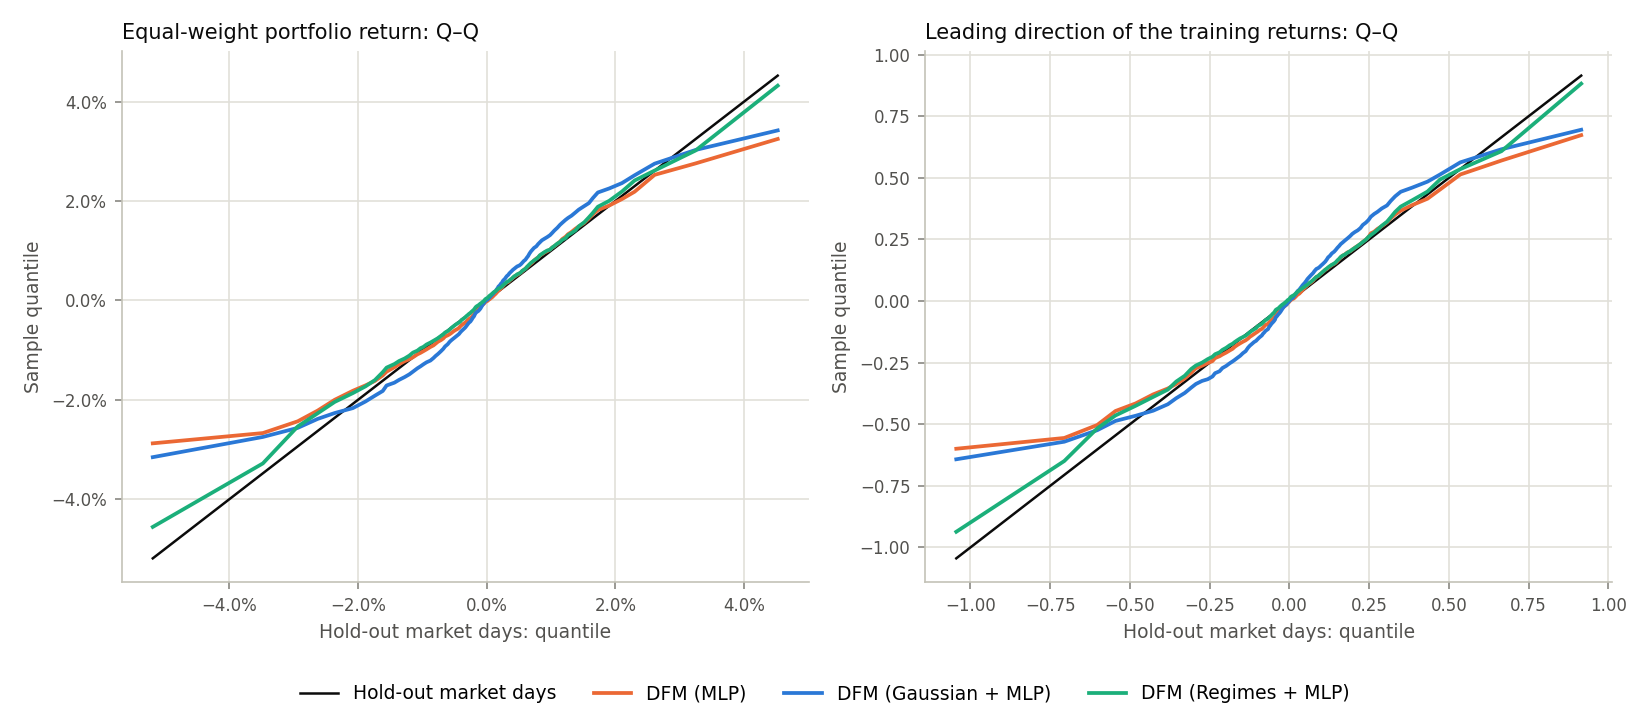

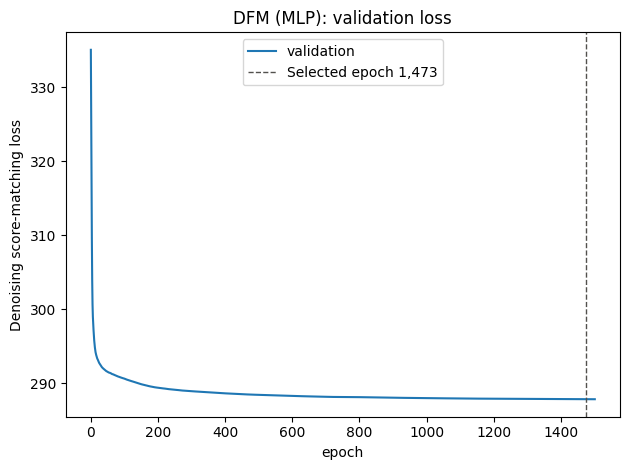

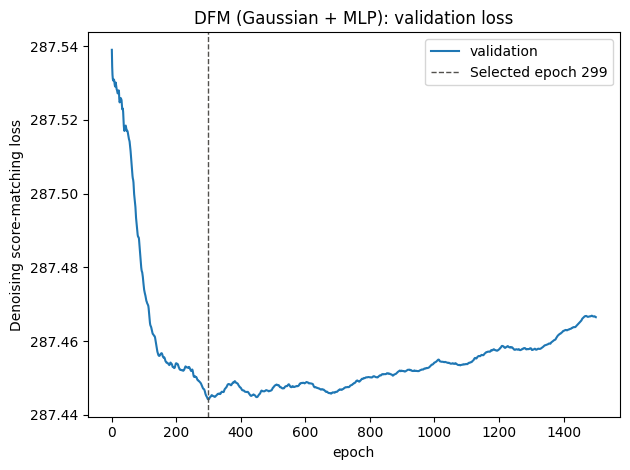

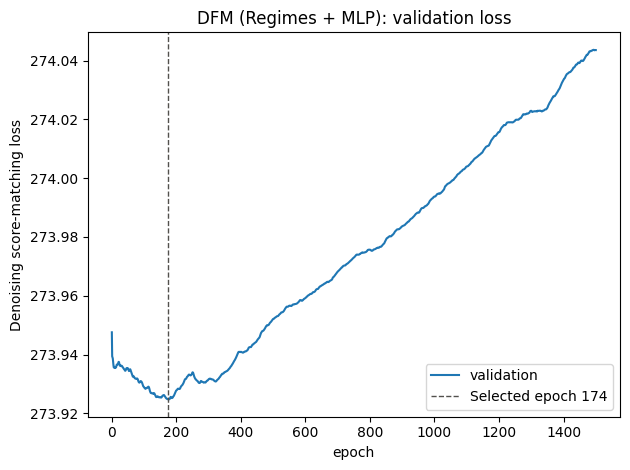

**Unconditional returns: values next to the hold-out market days.** The daily volatility level is the cross-sectional root mean square of the standardized returns of a day; its dispersion is its standard deviation over its mean. The events are the portfolio return below its 5% and 1% quantiles over the training days.

,Hold-out market days,DFM (MLP),DFM (Gaussian + MLP),DFM (Regimes + MLP)
Mean portfolio return,0.05%,0.06%,0.10%,0.10%
Portfolio volatility,1.32%,1.11%,1.30%,1.24%
5% quantile of the portfolio return,-1.98%,-1.77%,-2.12%,-1.82%
1% quantile of the portfolio return,-3.78%,-2.72%,-2.91%,-3.61%
Excess kurtosis of the portfolio return,9.05,0.84,0.02,5.92
Median excess kurtosis of the asset returns,10.57,0.10,0.03,2.41
Dispersion of the daily volatility level,0.53,0.21,0.23,0.44
Frequency of the 5% event,6.2%,5.1%,7.5%,5.3%
Frequency of the 1% event,1.5%,0.3%,0.3%,1.2%


**Unconditional returns: distances to the hold-out market days (lower is better).** Each source uses 3,000 rows. The market-vs-market reference is the same distance between training and validation days and the hold-out days: one draw of the sampling variation between two market samples, not a noise quantile.

,DFM (MLP),DFM (Gaussian + MLP),DFM (Regimes + MLP),Market-vs-market reference
Portfolio: KS distance to the hold-out days,0.042,0.079,0.029,0.019
Joint law: sliced W1 distance to the hold-out days,0.002,0.003,0.001,0.001
Covariance: relative error to the hold-out covariance,0.319,0.140,0.190,0.115


In [4]:
if not SAVED_RUN:
    run_market_unconditional(CONFIG, split, OUTPUT, networks=DFM_NETWORKS, verdict=GUIDED_NETWORK)
dfm_values, dfm_distances = show_market_unconditional(OUTPUT, networks=DFM_NETWORKS)

## 3. The conditional models

DFM (Regimes + MLP) is frozen. The three conditional models of the synthetic notebook (sections 3
to 5 there) are trained and sampled on it with the same recipe: both H models are trained on the
same unguided trajectories of the frozen DFM, and every sampler starts from the H-tilted initial
law and ends with the exact final step.

| Model | H | Sampler |
| --- | --- | --- |
| CDG-ML | Guo et al. (2026), no refinement | Guided Euler steps, exact final step |
| Refined CDG-ML | The five refinements | Guided Euler steps, exact final step |
| Refined CDG-ML + SMC | H of Refined CDG-ML | Guided steps corrected by SMC, exact final step |

The reduced coordinates $Y_t=(Z_t,U_t)$ that H reads do not contain the volatility level of this
DFM, which changes the probability of the event, so H is a coarser approximation here than on the
Gaussian population. The SMC correction does not rely on the accuracy of H: as the number of
particles grows, its rows follow the law DFM rejection samples.

## 4. Evaluate the conditional returns

| Source | How it is produced |
| --- | --- |
| Hold-out market days in the event | Evaluation days with $w^\top R\le C_q$ |
| DFM rejection sampling | Unguided draws of the frozen DFM on the same grid, keeping $w^\top R\le C_q$ |
| The three conditional models | Section 3 |

| Comparison | What it assesses |
| --- | --- |
| DFM rejection vs hold-out market days in the event | Error of the DFM's own conditional law |
| Conditional model vs DFM rejection | Error of the conditioning: learned H, guided integration |
| Conditional model vs hold-out market days in the event | Combined error |
| DFM rejection vs independent DFM rejection | Sampling variation at the same sample size |

The tables are those of the synthetic notebook, with the hold-out market days in the event in
place of the exact law. Per event, the output shows the validation loss of Refined CDG-ML and the
held-out diagnostics of both H models, then the portfolio CDF given the event and two Q–Q plots
against DFM rejection (the portfolio and the leading direction of the training returns), then
three tables: values next to the hold-out market days in the event, distances to them, and SMC
diagnostics. The figure draws `PLOT_SOURCES`; the tables list DFM rejection and every model.

Every distance uses the same number of rows for every source: the number of hold-out days in the
event (187 at 5% and 46 at 1%). Each sits next to its noise level: the 95% quantile, over 100
replicates, of the same distance between two bootstrap samples of that size drawn from all market
days in the event (hold-out, training and validation). With so few days, the comparisons with the
market are noisy, most at 1%.

After both events, the conditioning error compares every model with DFM rejection. DFM rejection
is drawn twice, independently; the distance between the two streams is the reference. The last
table puts the DFM rejection of DFM (Gaussian + MLP) and DFM (Regimes + MLP) next to the hold-out
market days in the event.

In [5]:
from market_benchmark.conditional import (
    conditional_folder, run_market_conditional, run_market_rejection_comparison, show_market_conditional,
    show_market_rejection_comparison,
)
from synthetic_benchmark.configuration import rejection_assessment
from synthetic_benchmark.reporting import conditioning_error_table, readable_conditioning_error

# Events computed and displayed; "0.05" skips the 1% event, whose DFM rejection streams are long,
# and "none" every event.
TAILS = tuple(float(tail) for tail in os.environ.get("MARKET_TAILS", "0.05,0.01").split(",")
              if tail.strip() not in ("", "none"))
# Guidance targets the frozen DFM (Regimes + MLP); the run folders carry the network's name.
GUIDED_CONFIG = network_config(CONFIG, GUIDED_NETWORK)
# Frozen DFMs whose DFM rejection is put beside the hold-out market days in the event.
REJECTION_NETWORKS = ("gaussian_mlp", "regime_mlp")
# Models drawn in the figure, beside DFM rejection and the hold-out market days; the tables list every model.
PLOT_SOURCES = ("refined_exact", "refined_smc")
# The H recipe of the synthetic notebook: 40k trajectories, 50 epochs, validation every 157 optimizer steps.
H_RECIPE = dict(
    plot_sources=PLOT_SOURCES,
    n_train=2_048 if CONFIG.mode == "smoke" else 40_000,
    n_validation=1_024 if CONFIG.mode == "smoke" else 2_000,
    n_test=1_024 if CONFIG.mode == "smoke" else 2_000,
    epochs=10 if CONFIG.mode == "smoke" else 50,
    validation_interval_steps=157,
    widths=(64, 64),
    initialization_seed=2027,
    lr=1e-3,
    batch_size=64,
    path_batch_size=256,
    train_seeds={"train": 32001, "validation": 32002, "test": 32003, "shuffle": 32004},
    n_samples=CONFIG.n_eval,
    sample_batch_size=256,
    guided_seed=42001,
    smc_seed=42011,
    smc_ess_threshold=0.5,
)
# Accepted rows per DFM rejection stream, by event. A DFM may put less mass than the market in the
# far tail, so a stream may draw up to 10 times the proposals expected at the nominal probability.
REJECTION_ROWS = {0.05: 128, 0.01: 64} if CONFIG.mode == "smoke" else {0.05: 1_000, 0.01: 1_000}
ASSESSMENT = dict(
    cap_factor=10,
    rejection_batch_size=2_048,
    rejection_seed=42003, rejection_reference_seed=42004, truth_reference_seed=42005,
    projection_seed=42006, matching_seed=42007, projections=64, noise_seed=42009,
)

### The 5% event

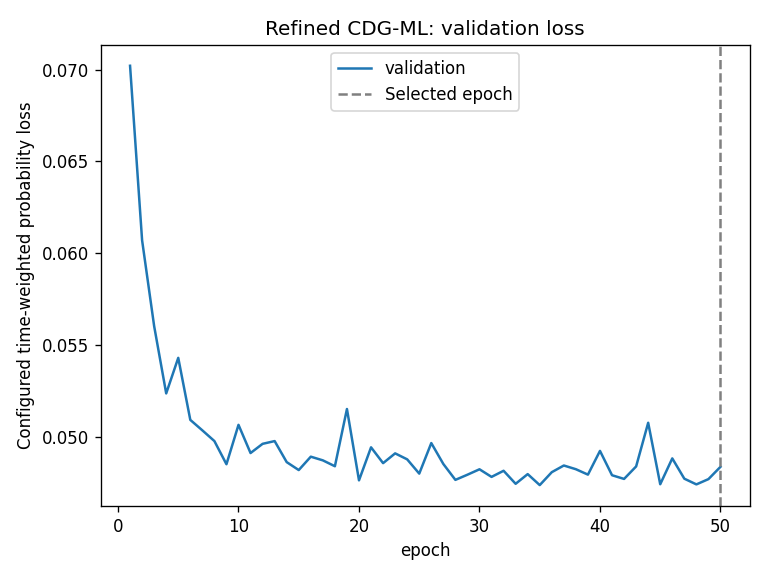

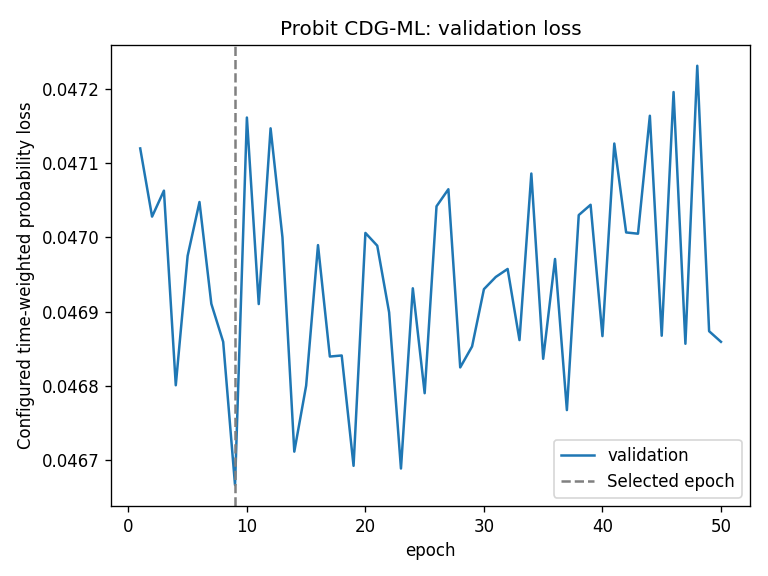

,Refined CDG-ML,CDG-ML,Probit CDG-ML
Held-out Brier loss,0.0238,0.0246,0.0235
Constant-probability Brier loss,0.0471,0.0471,0.0471
First-layer Tanh saturation,0.1853,0.2895,0.0122
Last-step probability RMSE,0.0381,0.1254,0.0010
Last-step gradient relative RMSE,0.8119,0.9960,0.0681
Last-step gradient cosine,0.9606,0.6503,1.0000
Selected epoch,50,38,9
Selected optimizer step,"31,086","23,236","5,495"


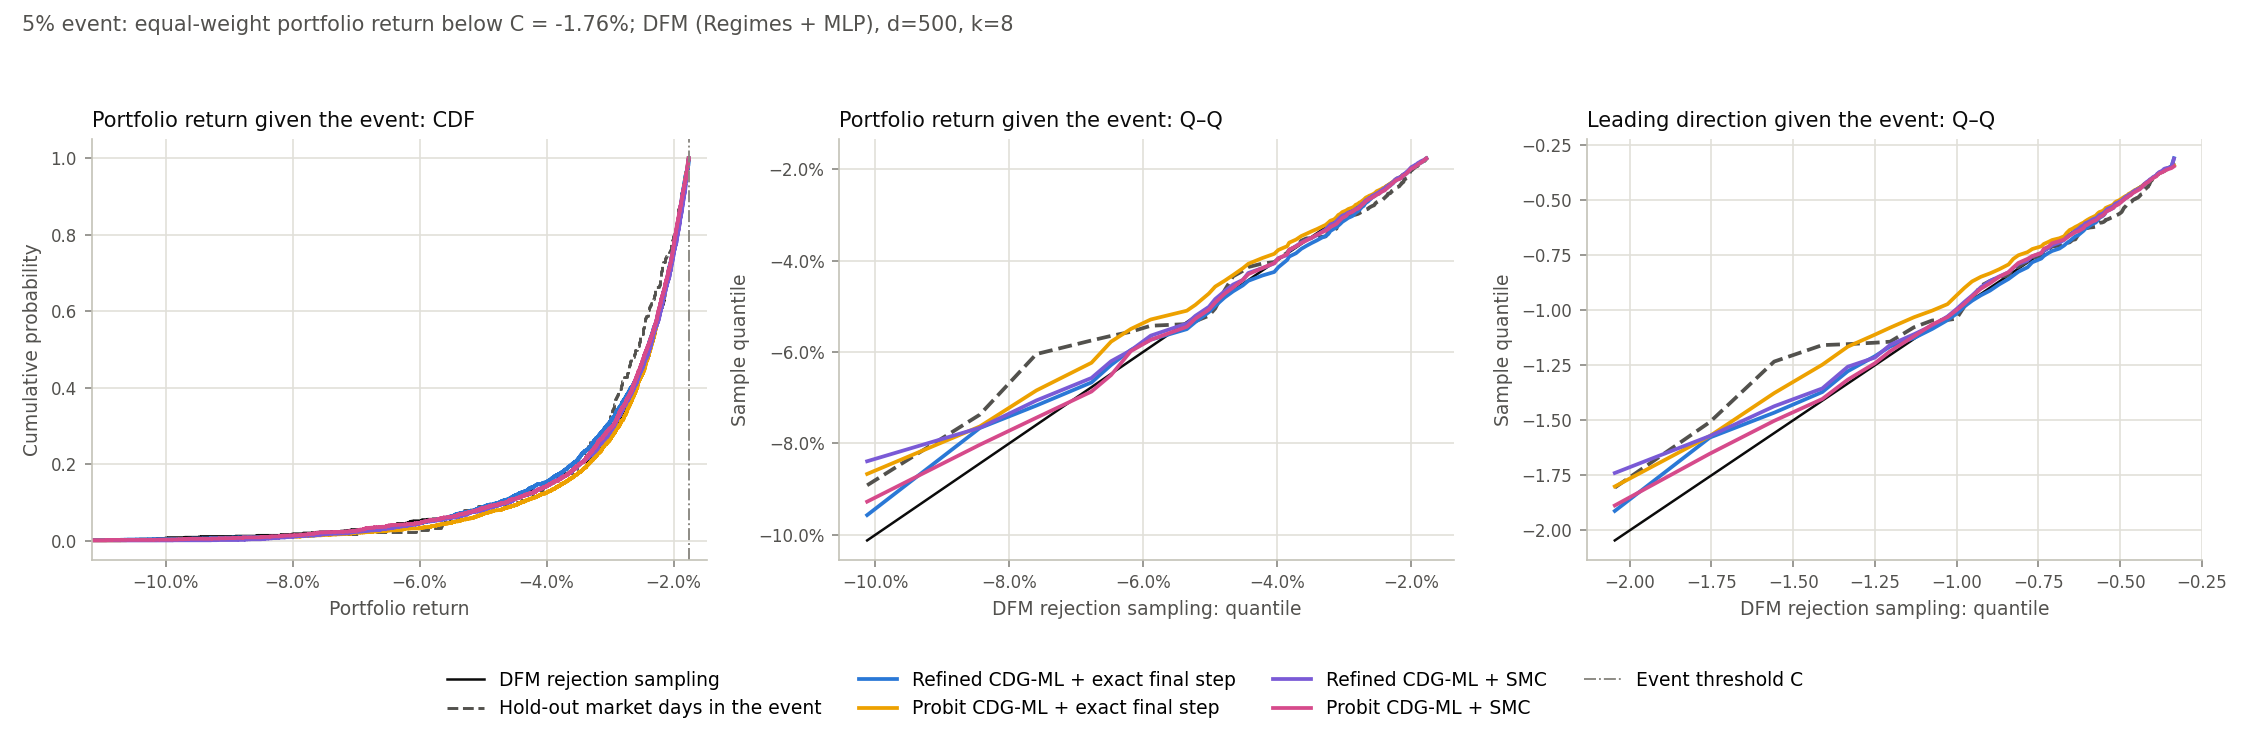

**5% event: values next to the hold-out market days in the event.**

,Hold-out market days in the event,DFM rejection,Refined CDG-ML,CDG-ML,Probit CDG-ML,Refined CDG-ML + SMC,Probit CDG-ML + SMC
Expected shortfall: mean return given the event,-2.95%,-2.90%,-2.93%,-2.93%,-2.81%,-2.86%,-2.91%
Volatility given the event,1.31%,1.47%,1.41%,1.41%,1.26%,1.32%,1.39%
Rows in the event,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
Rows,187,"1,000","3,000","3,000","3,000","3,000","3,000"
Event frequency without conditioning,6.23%,5.34%,—,—,—,—,—


**5% event: distances (lower is better).** Distances to DFM rejection measure the conditioning error (1,000 matched rows); distances to the hold-out market days in the event add the error of the DFM itself (187 rows). The same-source reference is the same distance between two independent DFM rejection streams, or between the hold-out and the training and validation days in the event: one draw of the sampling variation, not a noise quantile.

Refined CDG-ML  \
Compared with                     Metric                                 
DFM rejection                     Portfolio KS distance          0.032   
                                  Portfolio W1 distance       0.000598   
                                  Sliced W1 distance           0.00196   
Hold-out market days in the event Portfolio KS distance          0.155   
                                  Portfolio W1 distance        0.00239   
                                  Sliced W1 distance           0.00485   

                                                          CDG-ML  \
Compared with                     Metric                           
DFM rejection                     Portfolio KS distance    0.065   
                                  Portfolio W1 distance  0.00136   
                                  Sliced W1 distance     0.00181   
Hold-out market days in the event Portfolio KS distance    0.112   
                                  Portfolio W1 distance  0.00115   
                                  Sliced W1 distance     0.00448   

                                                        Probit CDG-ML  \
Compared with                     Metric                                
DFM rejection                     Portfolio KS distance         0.027   
                                  Portfolio W1 distance       0.00122   
                                  Sliced W1 distance          0.00195   
Hold-out market days in the event Portfolio KS distance          0.16   
                                  Portfolio W1 distance       0.00245   
                                  Sliced W1 distance          0.00451   

                                                        Refined CDG-ML + SMC  \
Compared with                     Metric                                       
DFM rejection                     Portfolio KS distance                0.037   
                                  Portfolio W1 distance             0.000715   
                                  Sliced W1 distance                 0.00171   
Hold-out market days in the event Portfolio KS distance                0.128   
                                  Portfolio W1 distance              0.00176   
                                  Sliced W1 distance                 0.00442   

                                                        Probit CDG-ML + SMC  \
Compared with                     Metric                                      
DFM rejection                     Portfolio KS distance               0.058   
                                  Portfolio W1 distance              0.0011   
                                  Sliced W1 distance                0.00192   
Hold-out market days in the event Portfolio KS distance               0.112   
                                  Portfolio W1 distance               0.002   
                                  Sliced W1 distance                 0.0049   

                                                        DFM rejection  \
Compared with                     Metric                                
DFM rejection                     Portfolio KS distance             —   
                                  Portfolio W1 distance             —   
                                  Sliced W1 distance                —   
Hold-out market days in the event Portfolio KS distance         0.198   
                                  Portfolio W1 distance        0.0025   
                                  Sliced W1 distance           0.0042   

                                                        Same-source reference  
Compared with                     Metric                                       
DFM rejection                     Portfolio KS distance                 0.023  
                                  Portfolio W1 distance              0.000462  
                                  Sliced W1 distance                  0.00164  
Hold-out market days in the event Portfolio KS distance                   

**Path weights (importance weights against the frozen DFM given the event).** Weighted values are consistent for the law DFM rejection samples, whatever H is; the effective sample size is the number of equally weighted rows with the same variance, as a share of the rows. The event frequency of a model is estimated from its weights.

,DFM rejection,Refined CDG-ML,CDG-ML,Probit CDG-ML
Effective sample size (share of rows),—,49.9%,43.3%,83.3%
DFM event frequency,5.34%,4.96%,5.25%,5.04%
Expected shortfall: unweighted,-2.90%,-2.93%,-2.93%,-2.81%
Expected shortfall: weighted,—,-2.92%,-2.86%,-2.92%
Volatility given the event: unweighted,1.47%,1.41%,1.41%,1.26%
Volatility given the event: weighted,—,1.36%,1.32%,1.37%
Portfolio KS distance to DFM rejection: unweighted,—,0.039,0.071,0.026
Portfolio KS distance to DFM rejection: weighted,—,0.047,0.030,0.043


**Sequential Monte Carlo correction.** The particles follow the guided sampler and are resampled in proportion to their weights when the effective sample size falls below the threshold, and once more before the exact final step. The rows are then equally weighted and, as the number of particles grows, follow the law DFM rejection samples. Rows that descend from the same path are not independent: the distinct shares say how many separate paths remain.

,DFM rejection,Refined CDG-ML + SMC,Probit CDG-ML + SMC
Resampling times,—,2,1
Lowest effective sample size (share of particles),—,35.2%,69.8%
Effective sample size before the last resampling,—,35.2%,69.8%
Distinct paths kept by the last resampling,—,90.6%,85.1%
Distinct starting points,—,70.9%,85.1%
DFM event frequency,5.34%,5.35%,5.08%


In [6]:
if 0.05 in TAILS:
    if not SAVED_RUN:
        run_market_conditional(
            GUIDED_CONFIG, split, OUTPUT, tail=0.05, label=GUIDED_NETWORK, **H_RECIPE,
            assessment_settings=rejection_assessment(0.05, REJECTION_ROWS[0.05], **ASSESSMENT),
        )
    conditional_5 = show_market_conditional(OUTPUT, 0.05, GUIDED_NETWORK)

### The 1% event

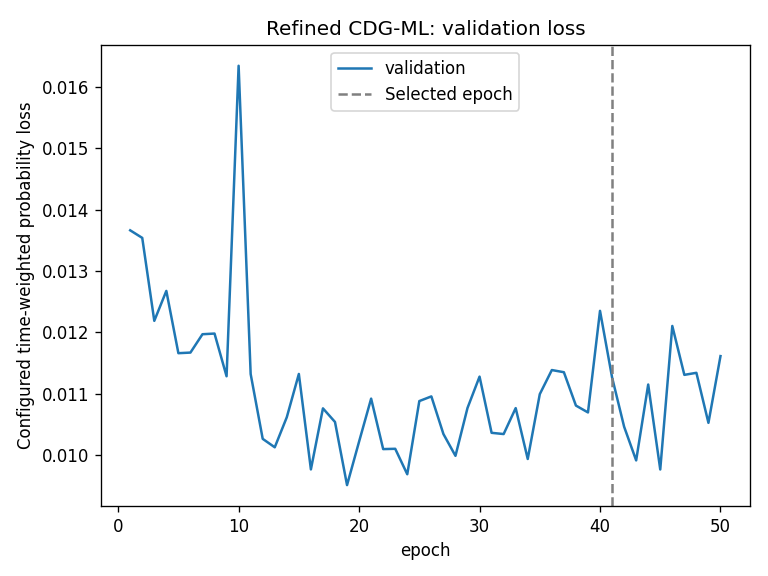

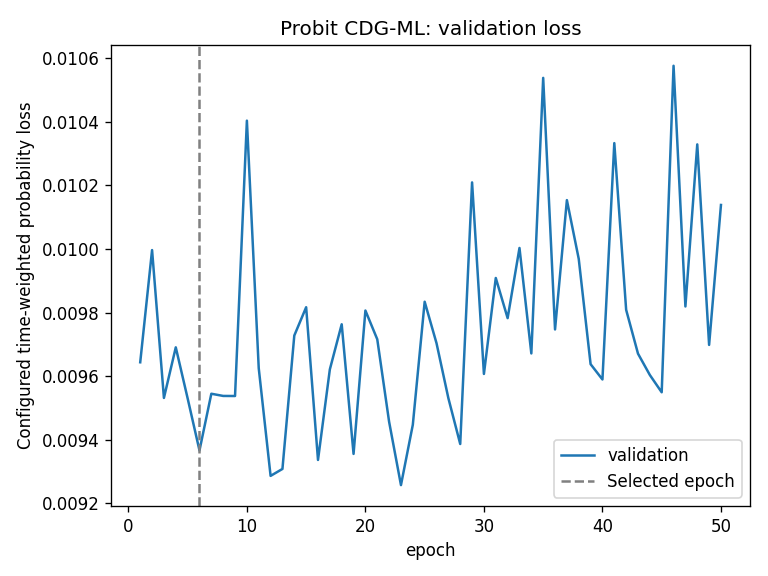

,Refined CDG-ML,CDG-ML,Probit CDG-ML
Held-out Brier loss,0.0050,0.0059,0.0050
Constant-probability Brier loss,0.0114,0.0114,0.0114
First-layer Tanh saturation,0.2166,0.3073,0.0680
Last-step probability RMSE,0.0167,0.0604,0.0000
Last-step gradient relative RMSE,—,—,—
Last-step gradient cosine,—,—,—
Selected epoch,41,39,6
Selected optimizer step,"25,120","24,178","3,297"


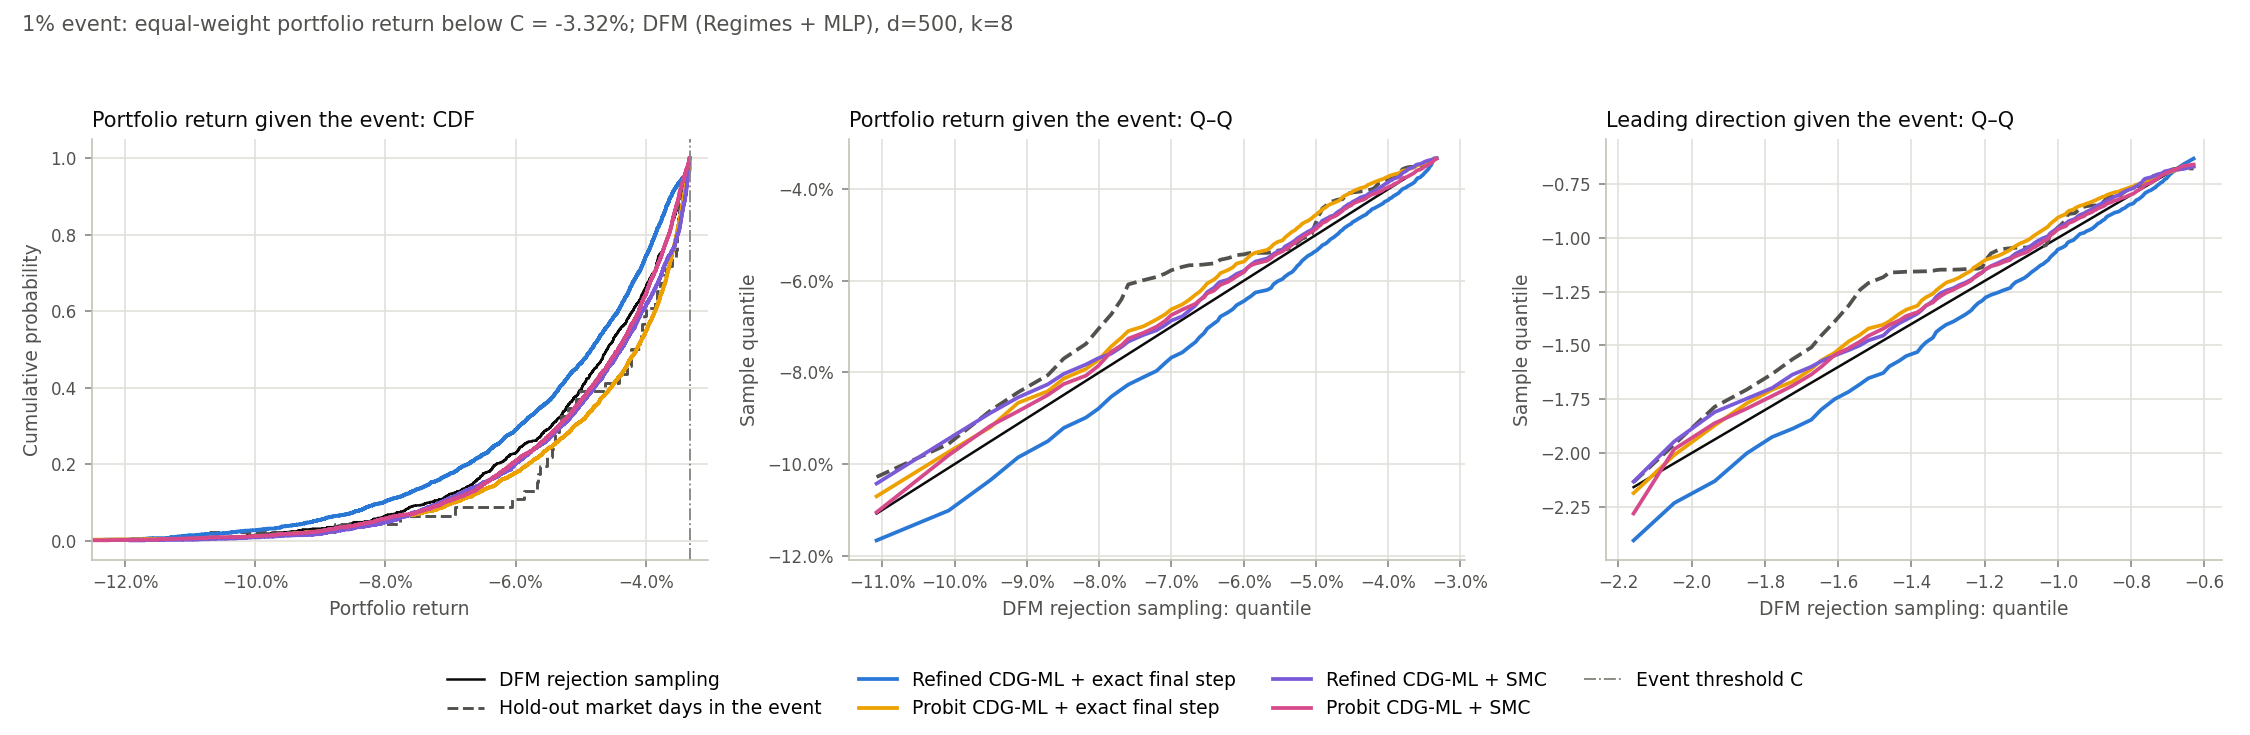

**1% event: values next to the hold-out market days in the event.**

,Hold-out market days in the event,DFM rejection,Refined CDG-ML,CDG-ML,Probit CDG-ML,Refined CDG-ML + SMC,Probit CDG-ML + SMC
Expected shortfall: mean return given the event,-4.71%,-5.04%,-5.38%,-5.60%,-4.74%,-4.85%,-4.93%
Volatility given the event,1.52%,1.62%,1.83%,1.97%,1.57%,1.53%,1.56%
Rows in the event,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
Rows,46,"1,000","3,000","3,000","3,000","3,000","3,000"
Event frequency without conditioning,1.53%,1.18%,—,—,—,—,—


**1% event: distances (lower is better).** Distances to DFM rejection measure the conditioning error (1,000 matched rows); distances to the hold-out market days in the event add the error of the DFM itself (46 rows). The same-source reference is the same distance between two independent DFM rejection streams, or between the hold-out and the training and validation days in the event: one draw of the sampling variation, not a noise quantile.

Refined CDG-ML  \
Compared with                     Metric                                 
DFM rejection                     Portfolio KS distance          0.093   
                                  Portfolio W1 distance        0.00272   
                                  Sliced W1 distance           0.00291   
Hold-out market days in the event Portfolio KS distance          0.283   
                                  Portfolio W1 distance        0.00937   
                                  Sliced W1 distance            0.0135   

                                                          CDG-ML  \
Compared with                     Metric                           
DFM rejection                     Portfolio KS distance    0.155   
                                  Portfolio W1 distance  0.00527   
                                  Sliced W1 distance     0.00397   
Hold-out market days in the event Portfolio KS distance    0.217   
                                  Portfolio W1 distance  0.00556   
                                  Sliced W1 distance      0.0131   

                                                        Probit CDG-ML  \
Compared with                     Metric                                
DFM rejection                     Portfolio KS distance         0.126   
                                  Portfolio W1 distance       0.00299   
                                  Sliced W1 distance          0.00434   
Hold-out market days in the event Portfolio KS distance         0.174   
                                  Portfolio W1 distance        0.0035   
                                  Sliced W1 distance          0.00967   

                                                        Refined CDG-ML + SMC  \
Compared with                     Metric                                       
DFM rejection                     Portfolio KS distance                0.096   
                                  Portfolio W1 distance              0.00186   
                                  Sliced W1 distance                 0.00325   
Hold-out market days in the event Portfolio KS distance                0.174   
                                  Portfolio W1 distance              0.00248   
                                  Sliced W1 distance                  0.0123   

                                                        Probit CDG-ML + SMC  \
Compared with                     Metric                                      
DFM rejection                     Portfolio KS distance               0.038   
                                  Portfolio W1 distance            0.000887   
                                  Sliced W1 distance                0.00248   
Hold-out market days in the event Portfolio KS distance               0.217   
                                  Portfolio W1 distance             0.00412   
                                  Sliced W1 distance                 0.0131   

                                                        DFM rejection  \
Compared with                     Metric                                
DFM rejection                     Portfolio KS distance             —   
                                  Portfolio W1 distance             —   
                                  Sliced W1 distance                —   
Hold-out market days in the event Portfolio KS distance         0.152   
                                  Portfolio W1 distance       0.00387   
                                  Sliced W1 distance           0.0126   

                                                        Same-source reference  
Compared with                     Metric                                       
DFM rejection                     Portfolio KS distance                  0.04  
                                  Portfolio W1 distance              0.000571  
                                  Sliced W1 distance                  0.00193  
Hold-out market days in the event Portfolio KS distance                   

**Path weights (importance weights against the frozen DFM given the event).** Weighted values are consistent for the law DFM rejection samples, whatever H is; the effective sample size is the number of equally weighted rows with the same variance, as a share of the rows. The event frequency of a model is estimated from its weights.

,DFM rejection,Refined CDG-ML,CDG-ML,Probit CDG-ML
Effective sample size (share of rows),—,12.1%,15.9%,26.0%
DFM event frequency,1.18%,1.09%,1.11%,1.10%
Expected shortfall: unweighted,-5.04%,-5.38%,-5.60%,-4.74%
Expected shortfall: weighted,—,-5.05%,-4.95%,-4.98%
Volatility given the event: unweighted,1.62%,1.83%,1.97%,1.57%
Volatility given the event: weighted,—,1.59%,1.57%,1.55%
Portfolio KS distance to DFM rejection: unweighted,—,0.093,0.174,0.125
Portfolio KS distance to DFM rejection: weighted,—,0.085,0.041,0.039


**Sequential Monte Carlo correction.** The particles follow the guided sampler and are resampled in proportion to their weights when the effective sample size falls below the threshold, and once more before the exact final step. The rows are then equally weighted and, as the number of particles grows, follow the law DFM rejection samples. Rows that descend from the same path are not independent: the distinct shares say how many separate paths remain.

,DFM rejection,Refined CDG-ML + SMC,Probit CDG-ML + SMC
Resampling times,—,3,3
Lowest effective sample size (share of particles),—,7.4%,49.5%
Effective sample size before the last resampling,—,7.4%,95.7%
Distinct paths kept by the last resampling,—,78.7%,97.3%
Distinct starting points,—,52.8%,60.4%
DFM event frequency,1.18%,1.24%,1.17%


In [7]:
if 0.01 in TAILS:
    if not SAVED_RUN:
        run_market_conditional(
            GUIDED_CONFIG, split, OUTPUT, tail=0.01, label=GUIDED_NETWORK, **H_RECIPE,
            assessment_settings=rejection_assessment(0.01, REJECTION_ROWS[0.01], **ASSESSMENT),
        )
    conditional_1 = show_market_conditional(OUTPUT, 0.01, GUIDED_NETWORK)

### Conditioning error of every model

In [8]:
# Read back the matched comparisons saved for each event: nothing is trained or sampled again.
if TAILS:
    saved_comparisons = {tail: pd.read_csv(OUTPUT / conditional_folder(tail, GUIDED_NETWORK) / "comparisons.csv")
                         for tail in TAILS}
    conditioning_error = conditioning_error_table(saved_comparisons)
    conditioning_error.to_csv(OUTPUT / "conditioning_error.csv")
    conditioning_note, conditioning_display = readable_conditioning_error(conditioning_error)
    display(Markdown(conditioning_note), conditioning_display)

**Conditioning error: distances to DFM rejection (lower is better).** Each distance compares 1,000 matched rows with the DFM rejection sample. The rejection-vs-rejection reference is the same distance between two independent DFM rejection streams of that size: one Monte Carlo draw, which describes sampling variation.

Refined CDG-ML   CDG-ML Probit CDG-ML  \
Event    Metric                                                        
5% event Portfolio KS distance          0.032    0.065         0.027   
         Portfolio W1 distance       0.000598  0.00136       0.00122   
         Sliced W1 distance           0.00196  0.00181       0.00195   
1% event Portfolio KS distance          0.093    0.155         0.126   
         Portfolio W1 distance        0.00272  0.00527       0.00299   
         Sliced W1 distance           0.00291  0.00397       0.00434   

                               Refined CDG-ML + SMC Probit CDG-ML + SMC  \
Event    Metric                                                           
5% event Portfolio KS distance                0.037               0.058   
         Portfolio W1 distance             0.000715              0.0011   
         Sliced W1 distance                 0.00171             0.00192   
1% event Portfolio KS distance                0.096               0.038   
         Portfolio W1 distance              0.00186            0.000887   
         Sliced W1 distance                 0.00325             0.00248   

                               Rejection-vs-rejection reference  
Event    Metric                                                  
5% event Portfolio KS distance                            0.023  
         Portfolio W1 distance                         0.000462  
         Sliced W1 distance                             0.00164  
1% event Portfolio KS distance                             0.04  
         Portfolio W1 distance                         0.000571  
         Sliced W1 distance                             0.00193

### DFM rejection of the frozen DFMs next to the market

DFM rejection of DFM (Gaussian + MLP), sampled here with the same settings, beside that of
DFM (Regimes + MLP): the error of each DFM's own conditional law, before any conditioning
method.

In [9]:
for tail in TAILS:
    if not SAVED_RUN:
        run_market_rejection_comparison(
            GUIDED_CONFIG, split, OUTPUT, tail=tail, networks=REJECTION_NETWORKS, label=GUIDED_NETWORK,
            assessment_settings=rejection_assessment(tail, REJECTION_ROWS[tail], **ASSESSMENT),
        )
    show_market_rejection_comparison(OUTPUT, tail)

**5% event: DFM rejection of each frozen DFM next to the hold-out market days in the event.** This is the error of the DFM itself, before any conditioning method. Distances are to the hold-out market days in the event (lower is better); the training and validation days in the event give one draw of the sampling variation between two market samples.

,Hold-out market days in the event,Training and validation days in the event,"DFM rejection, DFM (Gaussian + MLP)","DFM rejection, DFM (Regimes + MLP)"
Event frequency without conditioning,6.23%,5.32%,8.18%,5.34%
Expected shortfall: mean return given the event,-2.95%,-2.86%,-2.38%,-2.90%
Volatility given the event,1.31%,1.63%,0.54%,1.47%
Portfolio KS distance to the hold-out market days in the event,—,0.150,0.277,0.197
Sliced W1 distance to the hold-out market days in the event,—,0.00408,0.00755,0.00441
Rows compared,187,173,173,173


**1% event: DFM rejection of each frozen DFM next to the hold-out market days in the event.** This is the error of the DFM itself, before any conditioning method. Distances are to the hold-out market days in the event (lower is better); the training and validation days in the event give one draw of the sampling variation between two market samples.

,Hold-out market days in the event,Training and validation days in the event,"DFM rejection, DFM (Gaussian + MLP)","DFM rejection, DFM (Regimes + MLP)"
Event frequency without conditioning,1.53%,0.95%,0.52%,1.18%
Expected shortfall: mean return given the event,-4.71%,-5.50%,-3.77%,-5.04%
Volatility given the event,1.52%,2.38%,0.41%,1.62%
Portfolio KS distance to the hold-out market days in the event,—,0.194,0.452,0.129
Sliced W1 distance to the hold-out market days in the event,—,0.0129,0.0167,0.0141
Rows compared,46,31,31,31


**How to read the results.**
* A conditional model whose distances to DFM rejection are at or below the
  rejection-vs-rejection reference reproduces the DFM's conditional law up to sampling
  variation at that sample size.
* The distance of DFM rejection to the hold-out market days in the event is the part of the
  error that no conditioning method can remove: it belongs to the DFM. The last table compares
  this part for DFM (Gaussian + MLP) and DFM (Regimes + MLP).
* A low effective sample size in the SMC diagnostics means that H guides the paths poorly; the
  share of distinct paths then says how many separate paths the rows come from, and a small
  share means few independent rows.

**Limitations.**
* One DFM seed, one H initialization and one split of the days: variability across seeds and
  splits is not estimated.
* The panel has a survivorship bias, and days are treated as independent draws of one law.
  The regimes of DFM (Regimes + MLP) are independent across days: volatility clustering and
  changes of the law in time are still ignored.
* Few hold-out days are in the event, so the comparisons with the market are noisy.
* The 400 Euler steps of the sampler lose part of the tails of DFM (Regimes + MLP); more steps
  recover them, at a higher cost for the DFM and for every conditional model.

[METHODS.md](METHODS.md) gives the formulas behind these comparisons.